# Hands-on 6: Eksplorasi Dataset Sensor dengan pandas

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 4.

Tujuan: memahami struktur dataset sensor (`data/raw/room_sensor_week.csv`), konversi timestamp,
time-series index, ringkasan operasional, korelasi antar variabel, dan visualisasi eksploratif.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Bangkitkan Dataset 1 Minggu (interval 10 menit)

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_room_sensor_week.py"],
                   capture_output=True, text=True)
print(r.stdout)

[SUKSES] Dataset tersimpan: data/raw/room_sensor_week.csv (1008 baris)
          timestamp device_id  temperature_c  humidity_pct  co2_ppm  power_watt
2026-01-01 00:00:00    room01          23.99         66.76      431       85.57
2026-01-01 00:10:00    room01          23.98         69.47      457       83.39
2026-01-01 00:20:00    room01          23.64         67.00      431       90.09
2026-01-01 00:30:00    room01          23.24         68.95      437       90.72



## 2. Eksplorasi Struktur, Time Series, dan Korelasi

In [3]:
r = subprocess.run([sys.executable, "scripts/explore_sensor_dataset.py"],
                   capture_output=True, text=True)
print(r.stdout)

=== 5 baris pertama ===
             timestamp device_id  ...  co2_ppm  power_watt
0  2026-01-01 00:00:00    room01  ...      431       85.57
1  2026-01-01 00:10:00    room01  ...      457       83.39
2  2026-01-01 00:20:00    room01  ...      431       90.09
3  2026-01-01 00:30:00    room01  ...      437       90.72
4  2026-01-01 00:40:00    room01  ...      453       82.10

[5 rows x 6 columns]

=== Ukuran data ===
(1008, 6)

=== Nama kolom ===
['timestamp', 'device_id', 'temperature_c', 'humidity_pct', 'co2_ppm', 'power_watt']

=== Info dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      1008 non-null   object 
 1   device_id      1008 non-null   object 
 2   temperature_c  1008 non-null   float64
 3   humidity_pct   1008 non-null   float64
 4   co2_ppm        1008 non-null   int64  
 5   power_watt     1008 non

## 3. Visualisasi Eksploratif

In [4]:
r = subprocess.run([sys.executable, "scripts/plot_exploration.py"],
                   capture_output=True, text=True)
print(r.stdout)

[SUKSES] outputs/figures/explore_temperature.png
[SUKSES] outputs/figures/explore_co2.png
[SUKSES] outputs/figures/explore_humidity.png
[SUKSES] outputs/figures/explore_correlation.png



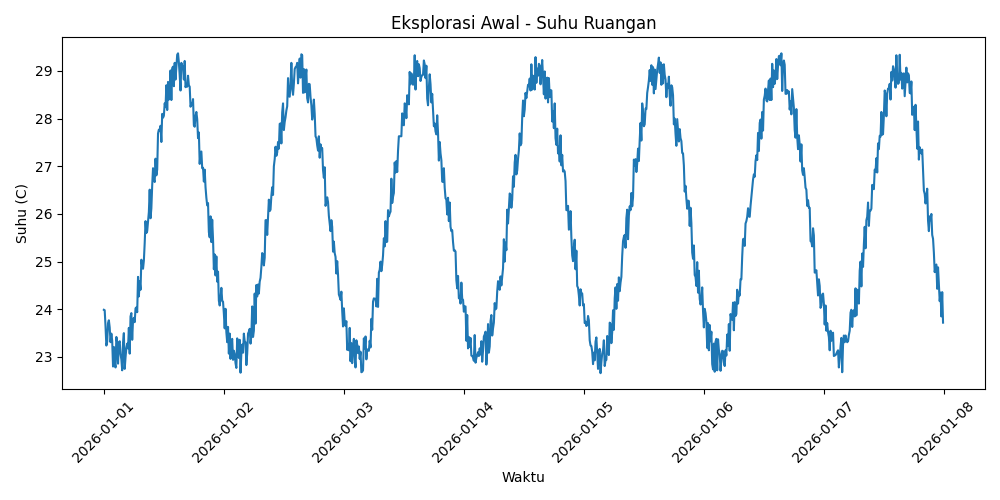

In [5]:
from IPython.display import Image
Image("outputs/figures/explore_temperature.png")

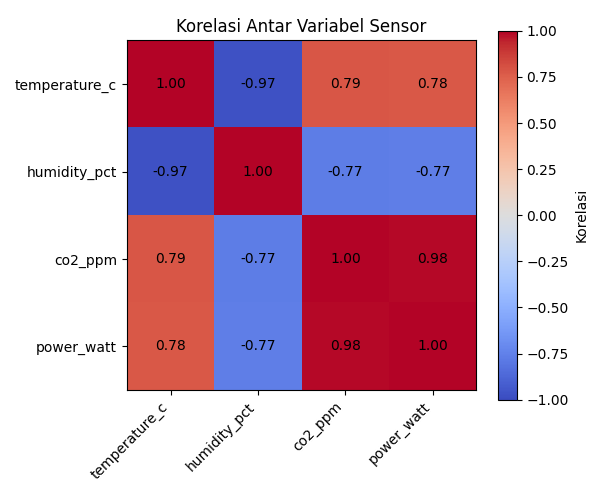

In [6]:
Image("outputs/figures/explore_correlation.png")

## Penutup

Dataset seminggu (1008 baris) menunjukkan pola harian yang realistis: suhu berkorelasi
negatif kuat dengan kelembaban (-0.97) dan positif dengan CO2/daya. Insight ini menjadi
dasar pembersihan dan resampling pada Hands-on 7.